In [1]:
import pandas as pd
import re
import os
from ast import literal_eval
from collections import Counter
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import matplotlib.lines as mlines
import matplotlib.ticker as ticker
from matplotlib import rcParams

In [2]:
username = os.path.expanduser('~')
username

'/home/ehdgus7279'

In [3]:
num_chiplets = 36
ns = 0.000000001

In [4]:
benchmarks = [
    # Low-sharing Apps
    "fdtd2d", "jacobi1d", "fastwalshtransform", "relu", "fft", "fir", 
    "sssp", "convolution2d", "color", "bitonicsort", "pagerank", "simpleconvolution",
    # High-sharing Apps
    'gups', 'syr2k', 'spmv', 'mis', 'stencil2d', 'gemm', 'lu', 
    'matrixmultiplication', 'mm2', 'mm3', 'gaussian', 'matrixtranspose', 
    'im2col', 'vgg16', 'bfs',
]

In [10]:
base_dir=f'{username}/mgvm/results/pc-state-traces'
date = "20260329-231119-dynamicdist"
trace_dir = f"{base_dir}/{date}"
print(f"{base_dir}/{date}")

/home/ehdgus7279/mgvm/results/pc-state-traces/20260329-231119-dynamicdist


In [11]:
cluster_size = 9
dist_type = 'dynamicdist'

In [7]:
def get_cluster_id(id):
    cluster_dim = 3
    row = id / 6
    col = id % 6

    partRow = row / cluster_dim
    partCol = col / cluster_dim

    return partRow*2 + partCol

In [12]:
def plot_pc_access_counts_over_time(df, benchmark, result_dir, op, save_fig=True):

    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np
    from matplotlib import rcParams

    # 고품질 설정
    plt.style.use('seaborn-v0_8-whitegrid')
    rcParams.update({
        'figure.figsize': (14, 9),    # 더 크게
        'figure.dpi': 300,
        'font.size': 12,
        'axes.titlesize': 16,
        'axes.labelsize': 14,
        'xtick.labelsize': 11,
        'ytick.labelsize': 11,
        'legend.fontsize': 12,
        'legend.frameon': True,
        'legend.framealpha': 0.95,
        'lines.linewidth': 3.5,
    })

    fig, ax = plt.subplots()

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', 
    '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
    unique_pcs = df['pc'].unique()

    # df_last에서 PC별 데이터 그리기
    if op == 'sum': 
        df_last = df.groupby(['time', 'pc'])['total'].sum().reset_index()
    elif op == 'mean':
        df_last = df.groupby(['time', 'pc'])['total'].mean().reset_index()
    if len(unique_pcs) > 10:
        top_pcs = df_last.groupby('pc')['total'].sum().nlargest(10).index
        df_last_subset = df_last[df_last['pc'].isin(top_pcs)]
    else:
        df_last_subset = df_last

    unique_pcs = df_last_subset['pc'].unique()

    for i, pc in enumerate(unique_pcs):
        pc_data = df_last_subset[df_last_subset['pc'] == pc].sort_values('time')
        
        color = colors[i % len(colors)]
        ax.plot(pc_data['time'], pc_data['total'], 
                label=f'PC {pc}',
                color=color,
                linewidth=3.5,
                alpha=1.0)  # 불투명하게

    ax.set_xlabel('Time (s)', fontsize=14, fontweight='bold')
    ax.set_ylabel('Total Access Count', fontsize=14, fontweight='bold')
    ax.set_title(f'{benchmark} Cache Line Access Patterns by PC over Time\n(Last per Time/PC)', 
                fontsize=16, fontweight='bold', pad=20)

    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', 
            frameon=True, shadow=True, ncol=1)

    if save_fig:
        plt.tight_layout()
        plt.savefig(f'{result_dir}/{benchmark}_pc_access_counts_over_time.png', 
                    dpi=300, bbox_inches='tight', 
                    facecolor='white', edgecolor='none')

In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib import rcParams

def plot_pc_state_over_time(df, benchmark, result_dir, save_fig=True):
    # 고품질 설정
    plt.style.use('seaborn-v0_8-whitegrid')
    rcParams.update({
        'figure.figsize': (14, 9),
        'figure.dpi': 300,
        'font.size': 12,
        'axes.titlesize': 16,
        'axes.labelsize': 14,
        'xtick.labelsize': 11,
        'ytick.labelsize': 11,
        'legend.fontsize': 12,
        'legend.frameon': True,
        'legend.framealpha': 0.95,
        'lines.linewidth': 3.5,
    })

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', 
              '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
    
    # 처리할 컬럼 리스트
    target_columns = ['pcs0', 'pcs1', 'pcs2', 'pcs3']

    for col in target_columns:
        # 데이터가 프레임에 존재하는지 확인
        if col not in df.columns:
            print(f"Warning: {col} not found in DataFrame. Skipping...")
            continue

        fig, ax = plt.subplots()

        # 시간과 PC별로 그룹화하여 해당 컬럼의 평균값 계산
        df_plot = df.groupby(['time', 'pc'])[col].mean().reset_index()
        unique_pcs = df_plot['pc'].unique()

        for i, pc in enumerate(unique_pcs):
            pc_data = df_plot[df_plot['pc'] == pc].sort_values('time')
            
            color = colors[i % len(colors)]
            ax.plot(pc_data['time'], pc_data[col], 
                    label=f'PC {pc}',
                    color=color,
                    linewidth=3.5,
                    alpha=1.0)

        # 레이블 및 타이틀 설정 (컬럼 이름 포함)
        ax.set_xlabel('Time (s)', fontweight='bold')
        ax.set_ylabel(f'Access Count ({col})', fontweight='bold')
        ax.set_title(f'{benchmark} - {col.upper()} State by PC over Time', 
                     fontsize=18, fontweight='bold', pad=20)

        ax.grid(True, alpha=0.3, linestyle='--')
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', 
                  frameon=True, shadow=True, ncol=1)

        if save_fig:
            plt.tight_layout()
            # 파일명에 pcs0, pcs1 등이 포함되도록 설정
            file_name = f'{result_dir}/{benchmark}_{col}_state_over_time.png'
            plt.savefig(file_name, dpi=300, bbox_inches='tight', 
                        facecolor='white', edgecolor='none')
            print(f"Saved: {file_name}")
        
        # 메모리 확보를 위해 현재 figure 닫기
        plt.close(fig)

In [53]:
date = "20260327-211411-dynamicdist"
# date = "20260329-231124-dynamicdist"
trace_dir = f"{base_dir}/{date}"
print(f"{trace_dir}")

for benchmark in benchmarks:
    trace_file = f"{trace_dir}/{benchmark}_{dist_type}_6x6_pc_state_trace.csv"
    print(trace_file)
    
    if not os.path.exists(trace_file):
        # print(f"{benchmark} not exists") 
        continue

    if benchmark != "spmv":
        continue

    df = pd.read_csv(trace_file)
    df = df[df['pc'] != 0]

    result_dir = f"./pc-state-over-time-old"
    os.makedirs(f"{result_dir}", exist_ok=True)
    
    plot_pc_state_over_time(df, benchmark, result_dir, save_fig=True)

/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/fdtd2d_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/jacobi1d_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/fastwalshtransform_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/relu_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/fft_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/fir_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/sssp_dynamicdist_6x6_pc_state_trace.csv
/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/convolution2d_dynamicdist_6x6_pc_sta

/home/ehdgus7279/mgvm/results/pc-state-traces/20260329-231124-dynamicdist/spmv_dynamicdist_6x6_pc_state_trace.csv


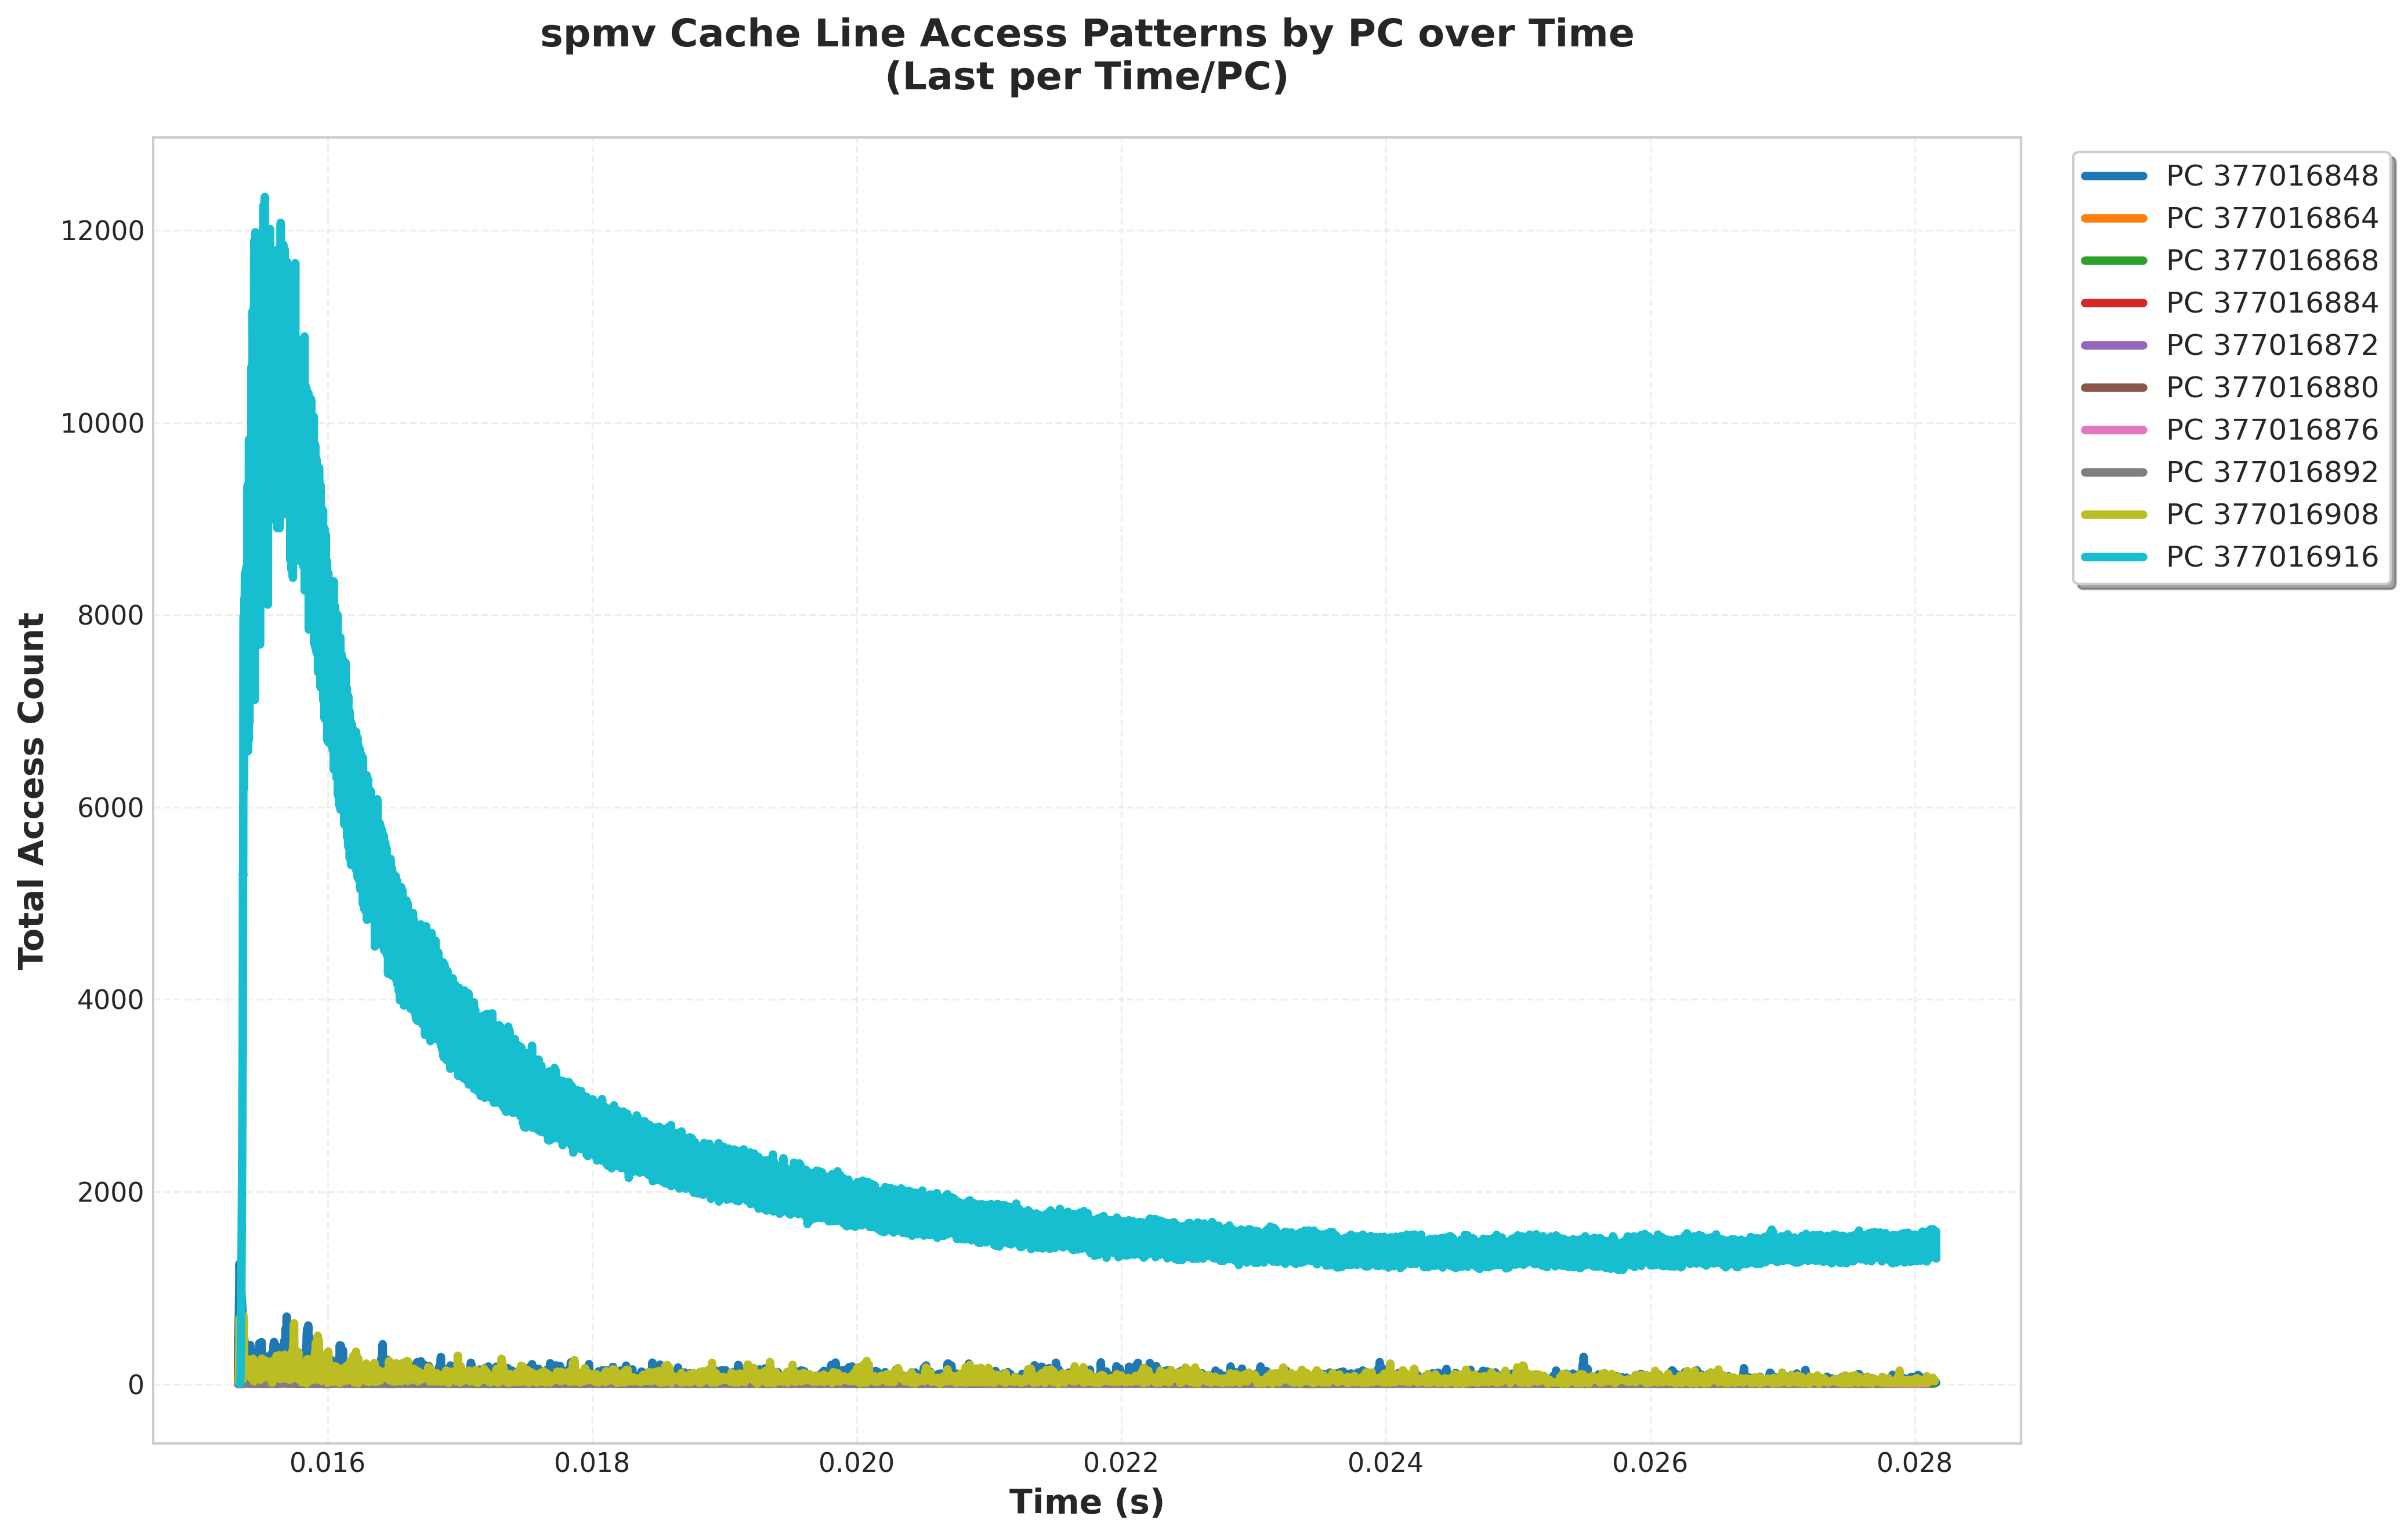

In [49]:
dist_type = 'dynamicdist'
# date = "20260327-211411-dynamicdist"
date = "20260329-231124-dynamicdist"
trace_dir = f"{base_dir}/{date}"

for benchmark in benchmarks:
    if benchmark != "spmv":
        continue

    trace_file = f"{trace_dir}/{benchmark}_{dist_type}_6x6_pc_state_trace.csv"
    print(trace_file)
    
    if not os.path.exists(trace_file):
        # print(f"{benchmark} not exists") 
        continue

    df = pd.read_csv(trace_file)
    df = df[df['pc'] != 0]

    op = 'mean'

    result_dir = f"./pc-access-count-{op}-over-time"
    os.makedirs(f"{result_dir}", exist_ok=True)
    
    plot_pc_access_counts_over_time(df, benchmark, result_dir, op, save_fig=True)

In [ ]:
benchmark='gemm'
trace_file = f"{trace_dir}/{benchmark}_{dist_type}_6x6_pc_state_trace.csv"
print(trace_file)

date="20260327-211411-dynamicdist"
df = pd.read_csv(trace_file)
result_dir = f"./"
plot_pc_state_over_time(df, benchmark, result_dir, save_fig=False)

/home/ehdgus7279/mgvm/results/pc-state-traces/20260327-211411-dynamicdist/gemm_dynamicdist_6x6_pc_state_trace.csv
